# APF3 · Solución de Machine Learning para la MiPYME
**Innovación y Transformación Digital · Sección 35024 · Grupo 04**
**MiPYME:** Sauna y Gimnasio LA CASCADA E.I.R.L. · **MVP:** Sistema de Reservas y Agenda (APF2)

**Problema ML (resumen):** clasificación binaria. Para cada cita registrada en el MVP, el modelo estima la probabilidad de **no_show** (el cliente no asiste) *antes* de la cita, para que recepción priorice los recordatorios de WhatsApp (Mago de Oz).

> **Declaración sobre los datos.** La empresa no autorizó compartir datos de clientes reales (Ley N.° 29733). Los dos seeds cargados en Supabase contienen datos **simulados** y están rotulados en la columna `origen`. Las relaciones entre variables son **supuestos plausibles** calibrados con las cifras de APF1/APF2; por eso los resultados son **indicativos y no generalizables** hasta validarlos con datos reales del piloto.

**Estructura:** 1 Configuración · 2 Datos y trazabilidad · 3 Coherencia · 4 EDA · 5 Limpieza y variables · 6 Partición y pipeline · 7 Línea base · 8 Modelos e hiperparámetros · 9 Selección · 10 Evaluación en test · 11 Interpretación · 12 Exportación e integración con el MVP · 13 Resumen.

## 1. Configuración y dependencias

In [1]:
# Dependencias para Colab: ML + conexión de solo lectura a Supabase.
%pip install -q "scikit-learn>=1.4" "pandas>=2.0" "numpy>=1.26" "matplotlib>=3.8" "joblib>=1.3" "supabase>=2.0"


In [2]:
import os, json, time, uuid, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_predict, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42          # semilla única para simulación, partición, CV y modelos
np.random.seed(RANDOM_STATE)
TZ = "America/Lima"
os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

print("Python-libs -> scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python-libs -> scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


## 2. Datos: origen, simulación y trazabilidad con el Contrato de Datos (APF2)

**Unidad de observación:** una cita (reserva) con estado final `asistio` o `no_asistio`.
**Variable objetivo:** `no_show` = 1 si el estado final es *no asistio*, 0 si *asistio*. Las citas `cancelo` y `pendiente` se excluyen (Contrato de Datos, Tabla 20 de APF2).
**Fuente:** tabla `citas` del MVP en Supabase. El notebook consulta únicamente campos operativos de las citas; no descarga nombres, DNI ni teléfonos de clientes.

El dataset se amplió dentro del propio MVP mediante dos seeds SQL con datos ficticios: la ampliación APF3 y los datos iniciales APF2. Ambos conjuntos son simulados. La procedencia se identifica por la fecha de la cita (hasta el 05/10/2026: ampliación APF3; desde el 06/10/2026: seed inicial APF2), pero **el origen se rotula `simulado` en todos los casos**. El objetivo `no_show` se deriva de `estado_asistencia`, porque no es una columna física de la tabla `citas`.

### 2.1 Parámetros de la simulación y su calibración
| Parámetro | Valor | Fuente de calibración |
|---|---|---|
| Tasa objetivo de no-shows | 20 % | APF1 (gerencia: 15–30 %, no auditable) y APF2 (panel: 19,6 %) |
| Citas por día en sede principal (lun–vie) | 20–30 | APF2, Tabla 1 (20, 27, 30 y 23 citas por día) |
| Aforos por franja | sauna 6 y 4; gimnasio 30 y 20 | APF2, Tabla 18/24 (valores de ejemplo por confirmar) |
| Recordatorios asignados al azar (50 %) | sí | APF2, nota de la Tabla 3 (evita el sesgo de enviar solo a clientes de riesgo) |
| Horario de atención 07:00–20:30 (solo en la simulación) | supuesto | Por confirmar con la empresa; la validación de datos usa un rango más amplio (05:00–22:00) |
| Efecto de antelación, confirmación, recordatorio, historial del cliente, fin de semana y franja | supuestos plausibles | **No medidos**: se validarán con el piloto real |

### 2.2 Conexión con Supabase
El notebook consulta un endpoint público de solo lectura desplegado como Supabase Edge Function. No requiere configurar **Colab → Secrets** ni introducir credenciales. El endpoint devuelve únicamente campos operativos de las citas y seudonimiza `id_cliente` para conservar el historial por cliente sin exponer el UUID original. La clave secreta de Supabase permanece en el entorno servidor de la Edge Function.


In [3]:
# --- Parámetros de la simulación (todo reproducible con RANDOM_STATE) ---
P = dict(inicio="2026-09-07",      # lunes; 4 semanas = duración prevista del piloto real (APF2, sección 2.2.6)
         dias=28, citas_dia_media=36, n_clientes=240,
         beta_a=1.2, beta_b=5.5,   # propensión individual a no asistir (media ~ 18 %)
         p_cancelo=0.04, p_recordatorio=0.50, tasa_objetivo=0.20)
FACTOR_DIA = {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.05, 5: 0.90, 6: 0.45}   # lunes=0 ... domingo=6
AFOROS = {("sauna", "Túpac Amaru"): 6, ("sauna", "Santa Rosa"): 4,
          ("gimnasio", "Túpac Amaru"): 30, ("gimnasio", "Santa Rosa"): 20}
SEDE_PRINCIPAL = "Túpac Amaru"
COLUMNAS_MVP = ["id_cita", "id_cliente", "servicio", "sede", "fecha_hora_cita", "fecha_hora_registro",
                "recordatorio_enviado_en", "confirmada_en", "estado_asistencia", "segundos_registro", "no_show"]

def _sigmoide(x): return 1 / (1 + np.exp(-x))

def simular_citas(seed=RANDOM_STATE):
    # Genera citas con la misma estructura que el CSV exportado por el MVP.
    rng = np.random.default_rng(seed)
    nc = P["n_clientes"]
    prop = rng.beta(P["beta_a"], P["beta_b"], nc)
    logit_cli = np.log(prop / (1 - prop))                 # propensión latente (no se exporta)
    actividad = rng.gamma(2.0, 1.0, nc); actividad /= actividad.sum()
    pref_sede = rng.random(nc) < 0.70                     # True -> sede principal
    pref_serv = rng.random(nc) < 0.60                     # True -> gimnasio
    id_cli = [str(uuid.UUID(bytes=rng.bytes(16), version=4)) for _ in range(nc)]
    horas = np.arange(7, 21, 0.5)                         # franjas de 30 min: 07:00 ... 20:30
    w = 1 + 2.0*np.exp(-((horas-8)/1.5)**2) + 2.5*np.exp(-((horas-19)/1.5)**2)
    w = w / w.sum()                                       # picos de mañana y de salida del trabajo

    filas, cupos = [], {}
    for dia in pd.date_range(P["inicio"], periods=P["dias"], freq="D", tz=TZ):
        n = min(rng.poisson(P["citas_dia_media"] * FACTOR_DIA[dia.dayofweek]), nc)
        elegidos = rng.choice(nc, size=n, replace=False, p=actividad)   # clientes más activos reservan más seguido
        for ci in elegidos:
            gym = pref_serv[ci] if rng.random() < 0.85 else (not pref_serv[ci])
            pri = pref_sede[ci] if rng.random() < 0.90 else (not pref_sede[ci])
            servicio = "gimnasio" if gym else "sauna"
            sede = SEDE_PRINCIPAL if pri else "Santa Rosa"
            for _ in range(10):                            # respeta el aforo de la franja
                h = float(rng.choice(horas, p=w))
                ts = dia + pd.Timedelta(hours=h)
                if cupos.get((servicio, sede, ts), 0) < AFOROS[(servicio, sede)]:
                    cupos[(servicio, sede, ts)] = cupos.get((servicio, sede, ts), 0) + 1
                    break
            else:
                continue
            u = rng.random()                               # antelación de la reserva
            if u < 0.35:                                   # mismo día
                reg = ts - pd.Timedelta(hours=rng.uniform(1.5, max(2.0, min(10.0, h - 6.5))))
            elif u < 0.75:                                 # 1 a 3 días antes
                reg = ts.normalize() - pd.Timedelta(days=int(rng.integers(1, 4))) + pd.Timedelta(hours=rng.uniform(8, 21))
            else:                                          # 4 a 10 días antes
                reg = ts.normalize() - pd.Timedelta(days=int(rng.integers(4, 11))) + pd.Timedelta(hours=rng.uniform(8, 21))
            ante = (ts - reg).total_seconds() / 3600

            rec = conf = pd.NaT
            if ante >= 3 and rng.random() < P["p_recordatorio"]:
                rec = ts - pd.Timedelta(hours=rng.uniform(2, min(5, ante - 0.5)))
            p_conf = 0.65 if pd.notna(rec) else 0.25
            if rng.random() < p_conf:
                if pd.notna(rec):
                    conf = min(rec + pd.Timedelta(hours=rng.uniform(0.2, 1.0)), ts - pd.Timedelta(minutes=30))
                elif ante > 1.5:
                    conf = reg + pd.Timedelta(hours=rng.uniform(0.5, ante - 0.5))

            dow = ts.dayofweek
            lp = (1.0*logit_cli[ci]
                  + 0.16*min(ante/24, 10) - (0.50 if ante < 4 else 0.0)      # más antelación, más no-shows
                  + {5: 0.35, 6: 0.50}.get(dow, 0.0)                          # fin de semana
                  + (0.30 if h >= 18 else (-0.25 if h < 9 else 0.0))          # noche vs mañana temprano
                  + (0.30 if servicio == "gimnasio" else 0.0)
                  - (0.60 if pd.notna(rec) else 0.0)                          # recordatorio
                  - (1.30 if pd.notna(conf) else 0.0))                        # confirmación del cliente
            filas.append(dict(id_cita=str(uuid.UUID(bytes=rng.bytes(16), version=4)), id_cliente=id_cli[ci],
                              servicio=servicio, sede=sede, fecha_hora_cita=ts, fecha_hora_registro=reg,
                              recordatorio_enviado_en=rec, confirmada_en=conf, _lp=lp,
                              _cancelo=bool(rng.random() < P["p_cancelo"]),
                              segundos_registro=round(float(rng.uniform(1, 6)), 2)))
    d = pd.DataFrame(filas)
    lp = d.loc[~d["_cancelo"], "_lp"].to_numpy()
    lo, hi = -10.0, 10.0                                   # calibra el intercepto a la tasa objetivo
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if _sigmoide(lp + mid).mean() < P["tasa_objetivo"] else (lo, mid)
    b0 = (lo + hi) / 2
    noshow = rng.random(len(d)) < _sigmoide(d["_lp"].to_numpy() + b0)
    d["estado_asistencia"] = np.where(d["_cancelo"], "cancelo", np.where(noshow, "no_asistio", "asistio"))
    d["no_show"] = np.where(d["_cancelo"], np.nan, noshow.astype(float))
    for c in ["fecha_hora_cita", "fecha_hora_registro", "recordatorio_enviado_en", "confirmada_en"]:
        d[c] = pd.to_datetime(d[c], utc=True)
    return d[COLUMNAS_MVP].sort_values("fecha_hora_cita").reset_index(drop=True)

USAR_SIMULACION_NOTEBOOK = False   # True solo si NO se dispone del CSV del MVP ampliado (genera datos dentro del notebook)
if USAR_SIMULACION_NOTEBOOK:
    df_sim = simular_citas()
    df_sim["origen"] = "simulado"
    df_sim["fuente"] = "simulacion_notebook_seed42"
else:
    df_sim = pd.DataFrame(columns=COLUMNAS_MVP + ["origen", "fuente"])
print("Citas simuladas dentro del notebook:", len(df_sim))

Citas simuladas dentro del notebook: 0


In [4]:
# --- Lectura automática del dataset desde el endpoint público de Supabase ---
# No requiere Colab Secrets ni credenciales de los integrantes/profesor.
import requests

URL_ENDPOINT_CITAS_ML = (
    "https://dlyferhackngkasvijrb.supabase.co/functions/v1/citas-ml"
)

respuesta = requests.get(URL_ENDPOINT_CITAS_ML, timeout=90)
if not respuesta.ok:
    try:
        detalle = respuesta.json().get("error", respuesta.text)
    except Exception:
        detalle = respuesta.text
    raise RuntimeError(
        f"No se pudo descargar el dataset (HTTP {respuesta.status_code}): {detalle}"
    )

payload = respuesta.json()
if not payload.get("ok") or "data" not in payload:
    raise RuntimeError(f"Respuesta inesperada del endpoint: {payload}")

df_mvp = pd.DataFrame(payload["data"])
if df_mvp.empty:
    raise ValueError(
        "El endpoint respondió correctamente, pero no devolvió citas. "
        "Verifica que los seeds estén cargados en public.citas."
    )

# Estas son las columnas operativas permitidas por el endpoint.
COLUMNAS_DB = [
    "id_cita", "id_cliente", "servicio", "sede", "fecha_hora_cita",
    "fecha_hora_registro", "estado_asistencia", "recordatorio_enviado_en",
    "confirmada_en", "segundos_registro"
]
faltan = set(COLUMNAS_DB) - set(df_mvp.columns)
assert not faltan, f"Faltan columnas en la respuesta del endpoint: {faltan}"

# El endpoint ya entrega id_cliente seudonimizado mediante HMAC.
# El target se deriva del estado final; canceladas/pendientes quedan sin target.
df_mvp["no_show"] = np.where(
    df_mvp["estado_asistencia"].isin(["asistio", "no_asistio"]),
    (df_mvp["estado_asistencia"] == "no_asistio").astype(float),
    np.nan
)

# Mantener exactamente el esquema que espera el resto del notebook.
df_mvp = df_mvp[COLUMNAS_MVP].copy()
for c in ["fecha_hora_cita", "fecha_hora_registro", "recordatorio_enviado_en", "confirmada_en"]:
    df_mvp[c] = pd.to_datetime(df_mvp[c], utc=True, errors="coerce")

# Los dos seeds son ficticios. La fecha distingue la procedencia, no si el dato es real.
FIN_AMPLIACION = pd.Timestamp("2026-10-05 23:59", tz=TZ)
ORIGEN_AMPLIACION = "simulado"
ORIGEN_ORIGINAL_APF2 = "simulado"
assert ORIGEN_AMPLIACION in ("real", "simulado") and ORIGEN_ORIGINAL_APF2 in ("real", "simulado")

es_ampliacion = df_mvp["fecha_hora_cita"].dt.tz_convert(TZ) <= FIN_AMPLIACION
df_mvp["origen"] = np.where(es_ampliacion, ORIGEN_AMPLIACION, ORIGEN_ORIGINAL_APF2)
df_mvp["fuente"] = np.where(es_ampliacion, "mvp_ampliacion_simulada", "mvp_original_apf2")

df_raw = pd.concat([df_sim, df_mvp], ignore_index=True) if len(df_sim) else df_mvp.copy()
df_raw.to_csv("dataset_apf3_lacascada.csv", index=False, date_format="%Y-%m-%dT%H:%M:%S+00:00")

print("Conexión con el endpoint de Supabase: OK")
print("Citas descargadas:", len(df_mvp))
print("Distribución por estado:", df_mvp["estado_asistencia"].value_counts(dropna=False).to_dict())
print("Citas de ampliación APF3:", int(es_ampliacion.sum()))
print("Citas del seed inicial APF2:", int((~es_ampliacion).sum()))
print("Total de filas en bruto:", len(df_raw))
print("Target derivado desde estado_asistencia; no_show no es una columna física de public.citas.")


Conexión con el endpoint de Supabase: OK
Citas descargadas: 1000
Distribución por estado: {'asistio': 761, 'no_asistio': 189, 'cancelo': 50}
Citas de ampliación APF3: 887
Citas del seed inicial APF2: 113
Total de filas en bruto: 1000
Target derivado desde estado_asistencia; no_show no es una columna física de public.citas.


### 2.2 Tabla de trazabilidad con el Contrato de Datos de APF2

In [5]:
cerr = df_raw[df_raw["estado_asistencia"].isin(["asistio", "no_asistio"])]
traza = pd.DataFrame([
    ["no_show (variable objetivo)", "estado_asistencia (MVP, Supabase)", "107 citas con estado final (21 positivos)",
     f"{len(cerr)} citas con estado final ({int(cerr['estado_asistencia'].eq('no_asistio').sum())} positivos)",
     "Se amplió el MVP con una simulación calibrada para cumplir ≥ 200 filas y ≥ 30 positivos"],
    ["servicio, sede", "tabla citas", "campos del contrato", "presentes", "Sin cambios. El CSV exporta sede «Túpac Amaru»; el diccionario de APF2 dice «Año Nuevo» (se normaliza)"],
    ["fecha_hora_cita, fecha_hora_registro", "tabla citas", "campos del contrato", "presentes", "Sin cambios (se derivan día, hora y antelación)"],
    ["recordatorio_enviado_en, confirmada_en", "tabla citas", "campos del contrato", "presentes", "Sin cambios (se usan como 0/1)"],
    ["tasa previa de no-show del cliente", "citas anteriores del mismo cliente", "variable predictora permitida", "derivada (últimos 30 días)", "Solo con citas anteriores; no filtra el target"],
    ["marcada_en, segundos_registro", "tabla citas", "excluidas (fuga)", "excluidas del modelo", "Se generan después del resultado; solo miden calidad del registro (H1)"],
    ["no_show en citas pendiente/canceló", "tabla citas de Supabase", "vacío (el contrato las excluye)",
     f"{int((df_raw['estado_asistencia'].isin(['pendiente', 'cancelo']) & df_raw['no_show'].notna()).sum())} filas con valor 0",
     "El notebook recalcula el objetivo desde estado_asistencia y excluye esas citas; la exportación del MVP debería dejarlo vacío (PROY)"],
    ["origen, fuente", "—", "no existía", "agregadas", "Exigidas por la consigna APF3 para rotular real / simulado"],
], columns=["Campo / variable objetivo", "Fuente", "Volumen esperado", "Volumen obtenido", "Cambio y justificación"])
pd.set_option("display.max_colwidth", 90, "display.width", 200)
traza

,Campo / variable objetivo,Fuente,Volumen esperado,Volumen obtenido,Cambio y justificación
0,no_show (variable objetivo),"estado_asistencia (MVP, Supabase)",107 citas con estado final (21 positivos),950 citas con estado final (189 positivos),Se amplió el MVP con una simulación calibrada para cumplir ≥ 200 filas y ≥ 30 positivos
1,"servicio, sede",tabla citas,campos del contrato,presentes,Sin cambios. El CSV exporta sede «Túpac Amaru»; el diccionario de APF2 dice «Año Nuevo...
2,"fecha_hora_cita, fecha_hora_registro",tabla citas,campos del contrato,presentes,"Sin cambios (se derivan día, hora y antelación)"
3,"recordatorio_enviado_en, confirmada_en",tabla citas,campos del contrato,presentes,Sin cambios (se usan como 0/1)
4,tasa previa de no-show del cliente,citas anteriores del mismo cliente,variable predictora permitida,derivada (últimos 30 días),Solo con citas anteriores; no filtra el target
5,"marcada_en, segundos_registro",tabla citas,excluidas (fuga),excluidas del modelo,Se generan después del resultado; solo miden calidad del registro (H1)
6,no_show en citas pendiente/canceló,tabla citas de Supabase,vacío (el contrato las excluye),0 filas con valor 0,El notebook recalcula el objetivo desde estado_asistencia y excluye esas citas; la exp...
7,"origen, fuente",—,no existía,agregadas,Exigidas por la consigna APF3 para rotular real / simulado


### 2.3 Diccionario de datos

In [6]:
diccionario = pd.DataFrame([
 ["id_cita", "texto (uuid)", "—", "Identificador único de la cita", "uuid único"],
 ["id_cliente", "texto (uuid)", "—", "Identificador seudónimo del cliente (no es DNI)", "uuid"],
 ["servicio", "categórica", "—", "Servicio reservado", "sauna | gimnasio"],
 ["sede", "categórica", "—", "Sede de la cita", "Túpac Amaru | Santa Rosa"],
 ["fecha_hora_cita", "fecha-hora (UTC)", "—", "Fecha y hora programadas", "≥ fecha_hora_registro; 05:00–22:00 (Lima)"],
 ["fecha_hora_registro", "fecha-hora (UTC)", "—", "Momento en que se creó la reserva", "≤ fecha_hora_cita"],
 ["recordatorio_enviado_en", "fecha-hora (UTC)", "—", "Cuándo se envió el recordatorio por WhatsApp (opcional)", "entre registro y cita"],
 ["confirmada_en", "fecha-hora (UTC)", "—", "Cuándo confirmó el cliente (opcional)", "entre registro y cita"],
 ["estado_asistencia", "categórica", "—", "Estado final de la cita", "pendiente | asistio | no_asistio | cancelo"],
 ["segundos_registro", "numérica", "segundos", "Tiempo clic → guardado (calidad del registro; NO predictora)", "0 – 60 (fuera de rango se anula)"],
 ["no_show", "binaria", "0/1", "Variable objetivo: 1 = no asistió", "0, 1 (vacío si cancelo/pendiente)"],
 ["origen", "categórica", "—", "Rótulo exigido por la consigna", "real | simulado"],
 ["fuente", "categórica", "—", "Procedencia del registro", "mvp_ampliacion_simulada | mvp_original_apf2"],
 ["antelacion_h", "numérica", "horas", "fecha_hora_cita − fecha_hora_registro", "0 – 720"],
 ["hora_cita", "numérica", "hora decimal (Lima)", "Hora de la cita", "7.0 – 20.5"],
 ["dia_semana / fin_de_semana", "categórica / binaria", "—", "Día de la cita; sábado o domingo", "lun…dom; 0/1"],
 ["franja", "categórica (solo EDA)", "—", "mañana (<12 h), tarde (12–18 h), noche (≥18 h)", "3 valores"],
 ["recordatorio_enviado, confirmada", "binarias", "0/1", "Hubo recordatorio / hubo confirmación", "0, 1"],
 ["n_citas_previas, tasa_previa_no_show", "numéricas", "citas; proporción", "Citas cerradas y proporción de no-shows del cliente en los 30 días previos", "≥ 0; 0–1 (NaN sin historial)"],
], columns=["Variable", "Tipo", "Unidad", "Descripción", "Rango válido"])
diccionario

,Variable,Tipo,Unidad,Descripción,Rango válido
0,id_cita,texto (uuid),—,Identificador único de la cita,uuid único
1,id_cliente,texto (uuid),—,Identificador seudónimo del cliente (no es DNI),uuid
2,servicio,categórica,—,Servicio reservado,sauna | gimnasio
3,sede,categórica,—,Sede de la cita,Túpac Amaru | Santa Rosa
4,fecha_hora_cita,fecha-hora (UTC),—,Fecha y hora programadas,≥ fecha_hora_registro; 05:00–22:00 (Lima)
5,fecha_hora_registro,fecha-hora (UTC),—,Momento en que se creó la reserva,≤ fecha_hora_cita
6,recordatorio_enviado_en,fecha-hora (UTC),—,Cuándo se envió el recordatorio por WhatsApp (opcional),entre registro y cita
7,confirmada_en,fecha-hora (UTC),—,Cuándo confirmó el cliente (opcional),entre registro y cita
8,estado_asistencia,categórica,—,Estado final de la cita,pendiente | asistio | no_asistio | cancelo
9,segundos_registro,numérica,segundos,Tiempo clic → guardado (calidad del registro; NO predictora),0 – 60 (fuera de rango se anula)


## 3. Preparación, variables derivadas y verificaciones de coherencia (criterios 4.2)

In [7]:
COLS_FECHA = ["fecha_hora_cita", "fecha_hora_registro", "recordatorio_enviado_en", "confirmada_en"]
MAPA_SEDE = {"Año Nuevo": "Túpac Amaru"}        # el diccionario de APF2 usa «Año Nuevo» para la sede principal
DIAS = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]
VENTANA_DIAS, MARGEN_H = 30, 2                   # historial: 30 días (igual que riesgo_clientes() del MVP); referencia = cita − 2 h
CORTE = pd.Timestamp.now(tz=TZ)                  # una cita con estado final no puede estar en el futuro respecto a hoy
HORARIO_MIN, HORARIO_MAX = 5.0, 22.0             # horario plausible de atención (Lima); por confirmar con la empresa

def preparar(raw):
    d = raw.copy()
    for c in COLS_FECHA:
        d[c] = pd.to_datetime(d[c], utc=True, errors="coerce").dt.tz_convert(TZ)
    d["sede"] = d["sede"].replace(MAPA_SEDE)
    d["antelacion_h"] = (d["fecha_hora_cita"] - d["fecha_hora_registro"]).dt.total_seconds() / 3600
    d["hora_cita"] = d["fecha_hora_cita"].dt.hour + d["fecha_hora_cita"].dt.minute / 60
    d["dia_semana"] = d["fecha_hora_cita"].dt.dayofweek.map(dict(enumerate(DIAS)))
    d["fin_de_semana"] = (d["fecha_hora_cita"].dt.dayofweek >= 5).astype(int)
    d["franja"] = np.select([d["hora_cita"] < 12, d["hora_cita"] < 18], ["mañana", "tarde"], "noche")
    d["recordatorio_enviado"] = d["recordatorio_enviado_en"].notna().astype(int)
    d["confirmada"] = d["confirmada_en"].notna().astype(int)
    d["no_show_calc"] = d["estado_asistencia"].map({"asistio": 0, "no_asistio": 1})
    return d

def limpieza_basica(d):
    # (1) Citas fuera del horario plausible de atención (probables registros de prueba): se excluyen.
    # (2) segundos_registro fuera de 0–60 s: campo NO predictor; se anula (NaN) porque mide pausas del usuario, no el guardado.
    fuera = (d["hora_cita"] < HORARIO_MIN) | (d["hora_cita"] > HORARIO_MAX)
    d = d[~fuera].copy()
    mal_seg = (d["segundos_registro"] < 0) | (d["segundos_registro"] > 60)
    d.loc[mal_seg, "segundos_registro"] = np.nan
    return d, {"filas excluidas por horario": int(fuera.sum()), "segundos_registro anulados": int(mal_seg.sum())}

def agregar_historial(d):
    # Historial del cliente usando SOLO citas cerradas anteriores (≤ cita − 2 h) y dentro de 30 días: sin fuga del target.
    d = d.sort_values("fecha_hora_cita").reset_index(drop=True)
    cerradas = d[d["estado_asistencia"].isin(["asistio", "no_asistio"])]
    por_cli = {k: g[["fecha_hora_cita", "estado_asistencia"]] for k, g in cerradas.groupby("id_cliente")}
    n_prev, ns_prev = np.zeros(len(d), int), np.zeros(len(d), int)
    for i, (cli, t) in enumerate(zip(d["id_cliente"], d["fecha_hora_cita"])):
        g = por_cli.get(cli)
        if g is None: continue
        ref = t - pd.Timedelta(hours=MARGEN_H)
        m = (g["fecha_hora_cita"] <= ref) & (g["fecha_hora_cita"] > ref - pd.Timedelta(days=VENTANA_DIAS))
        n_prev[i], ns_prev[i] = int(m.sum()), int((g.loc[m, "estado_asistencia"] == "no_asistio").sum())
    d["n_citas_previas"], d["n_no_show_previos"] = n_prev, ns_prev
    d["tasa_previa_no_show"] = np.where(n_prev > 0, ns_prev / np.maximum(n_prev, 1), np.nan)
    d["riesgo_heuristico_mvp"] = ((d["n_citas_previas"] >= 2) & (d["tasa_previa_no_show"] >= 0.30)).astype(int)
    return d

df_prep = preparar(df_raw)
print("Filas preparadas (antes de limpiar):", len(df_prep))

Filas preparadas (antes de limpiar): 1000


In [8]:
# ---------- Reglas de validación automatizables (criterios 2 y 3) ----------
def validar(d):
    v = {}
    v["cita anterior al registro"] = int((d["fecha_hora_cita"] < d["fecha_hora_registro"]).sum())
    v["recordatorio fuera de [registro, cita]"] = int(((d["recordatorio_enviado_en"] < d["fecha_hora_registro"]) | (d["recordatorio_enviado_en"] > d["fecha_hora_cita"])).sum())
    v["confirmación fuera de [registro, cita]"] = int(((d["confirmada_en"] < d["fecha_hora_registro"]) | (d["confirmada_en"] > d["fecha_hora_cita"])).sum())
    v["servicio no permitido"] = int((~d["servicio"].isin(["sauna", "gimnasio"])).sum())
    v["sede no permitida"] = int((~d["sede"].isin(["Túpac Amaru", "Santa Rosa"])).sum())
    v["estado no permitido"] = int((~d["estado_asistencia"].isin(["pendiente", "asistio", "no_asistio", "cancelo"])).sum())
    v["hora fuera de 05:00–22:00"] = int(((d["hora_cita"] < HORARIO_MIN) | (d["hora_cita"] > HORARIO_MAX)).sum())
    v["antelación > 720 h (30 días)"] = int((d["antelacion_h"] > 720).sum())
    cerr_ = d["estado_asistencia"].isin(["asistio", "no_asistio"])
    v["cita con estado final posterior a hoy"] = int((cerr_ & (d["fecha_hora_cita"] > CORTE)).sum())
    v["duplicados (cliente, servicio, fecha-hora)"] = int(d.duplicated(["id_cliente", "servicio", "fecha_hora_cita"]).sum())
    act = d[d["estado_asistencia"] != "cancelo"]
    ocup = act.groupby(["servicio", "sede", "fecha_hora_cita"]).size().rename("n").reset_index()
    ocup["cap"] = [AFOROS[(s, se)] for s, se in zip(ocup["servicio"], ocup["sede"])]
    v["franjas que exceden el aforo"] = int((ocup["n"] > ocup["cap"]).sum())
    return pd.Series(v, name="violaciones")

def avisos_export(d):
    # Hallazgos informativos que no afectan al modelo (se documentan en el informe).
    sin_final = d["estado_asistencia"].isin(["pendiente", "cancelo"])
    return pd.Series({"target no_show en pendiente/canceló (debe ser nulo)": int((sin_final & d["no_show"].notna()).sum()),
                      "segundos_registro fuera de 0–60 s (campo no predictor)": int(((d["segundos_registro"] < 0) | (d["segundos_registro"] > 60)).sum())},
                     name="filas")

viol_antes = validar(df_prep)
df_lim, log_limpieza = limpieza_basica(df_prep)
df = agregar_historial(df_lim)                 # el historial se calcula con el dataset ya depurado
viol = validar(df)
print("Tratamiento aplicado:", log_limpieza)
display(pd.DataFrame({"antes de limpiar": viol_antes, "después de limpiar": viol}))
print("\nHallazgos informativos (antes de limpiar):")
display(avisos_export(df_prep).to_frame())
print("Filas del dataset depurado:", len(df), "| columnas:", df.shape[1])

Tratamiento aplicado: {'filas excluidas por horario': 0, 'segundos_registro anulados': 0}


,antes de limpiar,después de limpiar
cita anterior al registro,0,0
"recordatorio fuera de [registro, cita]",0,0
"confirmación fuera de [registro, cita]",0,0
servicio no permitido,0,0
sede no permitida,0,0
estado no permitido,0,0
hora fuera de 05:00–22:00,0,0
antelación > 720 h (30 días),0,0
cita con estado final posterior a hoy,0,0
"duplicados (cliente, servicio, fecha-hora)",0,0



Hallazgos informativos (antes de limpiar):


,filas
target no_show en pendiente/canceló (debe ser nulo),0
segundos_registro fuera de 0–60 s (campo no predictor),0


Filas del dataset depurado: 1000 | columnas: 25


In [9]:
# ---------- Ficha de coherencia (criterios 1, 2, 3, 4, 6 y 7; el 5 se cierra tras evaluar el modelo) ----------
dm = df[df["estado_asistencia"].isin(["asistio", "no_asistio"])].copy()
dm["no_show"] = dm["no_show_calc"].astype(int)

sim = df[df["fuente"].isin(["mvp_ampliacion_simulada", "simulacion_notebook_seed42"])]
por_dia_ppal = (sim[(sim["sede"] == SEDE_PRINCIPAL) & (sim["fecha_hora_cita"].dt.dayofweek < 5)]
                .groupby(sim["fecha_hora_cita"].dt.date).size())
tasa = dm["no_show"].mean()

ante_bins = pd.cut(dm["antelacion_h"], [0, 4, 24, 72, 168, 721], right=False,
                   labels=["<4 h", "4–24 h", "1–3 d", "3–7 d", "≥7 d"])
t_ante = dm.groupby(ante_bins, observed=True)["no_show"].mean()
t_conf = dm.groupby("confirmada")["no_show"].mean()
t_rec = dm.groupby("recordatorio_enviado")["no_show"].mean()
t_fds = dm.groupby("fin_de_semana")["no_show"].mean()

por_origen = dm.groupby(["origen", "fuente"]).agg(citas=("no_show", "size"), tasa_no_show=("no_show", "mean"),
                                                   antelacion_mediana_h=("antelacion_h", "median")).round(3)
hay_real = bool((dm["origen"] == "real").any())
if hay_real:
    t_or = dm.groupby("origen")["no_show"].mean()
    estado7 = "OK" if ("simulado" not in t_or or abs(t_or["real"] - t_or["simulado"]) <= 0.10) else "REVISAR"
else:
    estado7 = "OK (sin datos reales)"
REGLAS_LOGICAS = ["cita anterior al registro", "recordatorio fuera de [registro, cita]", "confirmación fuera de [registro, cita]",
                  "duplicados (cliente, servicio, fecha-hora)", "franjas que exceden el aforo",
                  "cita con estado final posterior a hoy"]
v_rangos = int(viol.drop(REGLAS_LOGICAS).sum())      # violaciones de rango/unidades del diccionario (después de limpiar)
v_logicas = int(viol[REGLAS_LOGICAS].sum())          # violaciones de reglas lógicas y temporales (después de limpiar)
r_antes = int(viol_antes.drop(REGLAS_LOGICAS).sum()); l_antes = int(viol_antes[REGLAS_LOGICAS].sum())
n_seg = int(avisos_export(df_prep)["segundos_registro fuera de 0–60 s (campo no predictor)"])
ficha = pd.DataFrame([
 ["1. Escala del negocio", f"Citas/día en sede principal (lun–vie): media {por_dia_ppal.mean():.1f} (APF2: 20–30). Tasa de no-shows {tasa:.1%} (APF1: 15–30 %; APF2: 19,6 %)",
  "OK" if 18 <= por_dia_ppal.mean() <= 32 and 0.15 <= tasa <= 0.30 else "REVISAR"],
 ["2. Rangos y unidades", f"Detectadas {r_antes} (citas fuera de horario); tratamiento: {log_limpieza['filas excluidas por horario']} filas excluidas; quedan {v_rangos}. Además {n_seg} valores de segundos_registro fuera de 0–60 s (campo no predictor), anulados", "OK" if v_rangos == 0 else "REVISAR"],
 ["3. Consistencia lógica y temporal", f"Detectadas {l_antes} y quedan {v_logicas} (orden de fechas, duplicados, aforo y estado final posterior a hoy)", "OK" if v_logicas == 0 else "REVISAR"],
 ["4. Relaciones plausibles (≥ 2)", f"No-show: confirmada {t_conf.get(1, np.nan):.1%} vs no confirmada {t_conf.get(0, np.nan):.1%}; con recordatorio {t_rec.get(1, np.nan):.1%} vs sin {t_rec.get(0, np.nan):.1%}; antelación ≥7 d {t_ante.iloc[-1]:.1%} vs <4 h {t_ante.iloc[0]:.1%}; fin de semana {t_fds.get(1, np.nan):.1%} vs entre semana {t_fds.get(0, np.nan):.1%}",
  "OK" if (t_conf[0] > t_conf[1]) and (t_rec[0] > t_rec[1]) and (t_ante.iloc[-1] > t_ante.iloc[0]) else "REVISAR"],
 ["5. Señal ni nula ni perfecta", "Se verifica con las métricas de test (sección 10)", "pendiente"],
 ["6. Coherencia con APF2", f"Columnas del Contrato de Datos presentes: {set(COLUMNAS_MVP) <= set(df_raw.columns)}", "OK" if set(COLUMNAS_MVP) <= set(df_raw.columns) else "REVISAR"],
 ["7. Mezcla real + simulado", ("Hay registros reales y simulados: ver la comparación por origen debajo" if hay_real else "No hay registros rotulados como reales: todo el dataset es simulado (ver tabla por origen/fuente)"),
  estado7],
], columns=["Criterio", "Qué se verificó / resultado", "Estado"])
display(ficha)
print("\nComparación por origen y fuente (criterio 7):")
display(por_origen)

,Criterio,Qué se verificó / resultado,Estado
0,1. Escala del negocio,Citas/día en sede principal (lun–vie): media 21.3 (APF2: 20–30). Tasa de no-shows 19.9...,OK
1,2. Rangos y unidades,Detectadas 0 (citas fuera de horario); tratamiento: 0 filas excluidas; quedan 0. Ademá...,OK
2,3. Consistencia lógica y temporal,"Detectadas 0 y quedan 0 (orden de fechas, duplicados, aforo y estado final posterior a...",OK
3,4. Relaciones plausibles (≥ 2),No-show: confirmada 10.2% vs no confirmada 26.2%; con recordatorio 13.0% vs sin 24.7%;...,OK
4,5. Señal ni nula ni perfecta,Se verifica con las métricas de test (sección 10),pendiente
5,6. Coherencia con APF2,Columnas del Contrato de Datos presentes: True,OK
6,7. Mezcla real + simulado,No hay registros rotulados como reales: todo el dataset es simulado (ver tabla por ori...,OK (sin datos reales)



Comparación por origen y fuente (criterio 7):


citas  tasa_no_show  antelacion_mediana_h
origen   fuente                                                            
simulado mvp_ampliacion_simulada    843         0.199                35.777
         mvp_original_apf2          107         0.196                12.017

## 4. Análisis exploratorio (EDA)

In [10]:
print("Estadísticos descriptivos (citas con estado final):")
display(dm[["antelacion_h", "hora_cita", "n_citas_previas", "tasa_previa_no_show"]].describe().round(2))
bal = dm["no_show"].value_counts().rename({0: "asistió (0)", 1: "no asistió (1)"})
print("\nBalance de clases:\n", bal.to_string(), f"\nProporción de la clase minoritaria: {dm['no_show'].mean():.1%}")
print("Filas:", len(dm), "| positivos (≥ 30 exigidos):", int(dm['no_show'].sum()))

Estadísticos descriptivos (citas con estado final):


,antelacion_h,hora_cita,n_citas_previas,tasa_previa_no_show
count,950.00,950.00,950.00,692.00
mean,58.76,14.33,2.24,0.17
std,67.42,4.67,2.28,0.28
min,1.51,6.00,0.00,0.00
25%,6.81,9.00,0.00,0.00
50%,30.75,15.50,2.00,0.00
75%,79.30,18.50,3.00,0.33
max,250.14,21.00,12.00,1.00



Balance de clases:
 no_show
asistió (0)       761
no asistió (1)    189 
Proporción de la clase minoritaria: 19.9%
Filas: 950 | positivos (≥ 30 exigidos): 189


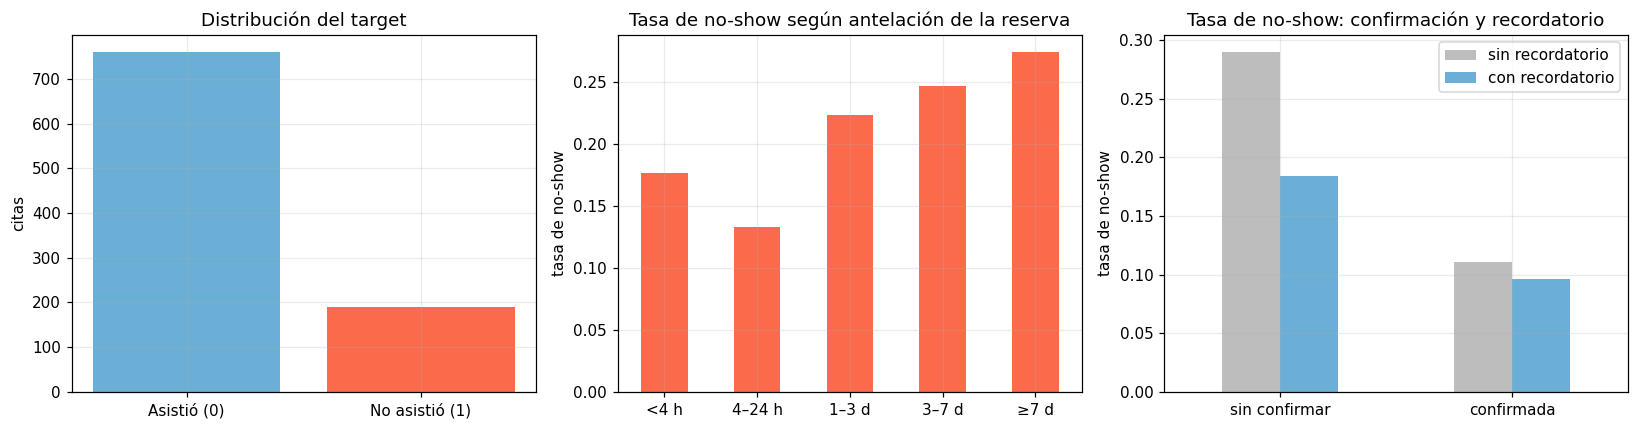

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(["Asistió (0)", "No asistió (1)"], [(dm["no_show"] == 0).sum(), (dm["no_show"] == 1).sum()], color=["#6baed6", "#fb6a4a"])
ax[0].set_title("Distribución del target"); ax[0].set_ylabel("citas")
t_ante.plot(kind="bar", ax=ax[1], color="#fb6a4a", rot=0)
ax[1].set_title("Tasa de no-show según antelación de la reserva"); ax[1].set_ylabel("tasa de no-show"); ax[1].set_xlabel("")
tt = dm.groupby(["confirmada", "recordatorio_enviado"])["no_show"].mean().unstack()
tt.index = ["sin confirmar", "confirmada"]; tt.columns = ["sin recordatorio", "con recordatorio"]
tt.plot(kind="bar", ax=ax[2], rot=0, color=["#bdbdbd", "#6baed6"])
ax[2].set_title("Tasa de no-show: confirmación y recordatorio"); ax[2].set_ylabel("tasa de no-show")
plt.tight_layout(); plt.savefig("figuras/eda_1_target_antelacion_confirmacion.png", bbox_inches="tight"); plt.show()

**Conclusión Figura 1.** La clase positiva es ≈ 20 %: el desbalance es moderado, por lo que *accuracy* engaña (un modelo que siempre diga «asistirá» tendría ≈ 80 %) y se priorizan recall y F1/F2 con partición estratificada. El no-show sube con la antelación de la reserva y baja con la confirmación y el recordatorio; son relaciones esperadas por el negocio (supuestos de la simulación, por validar con datos reales).

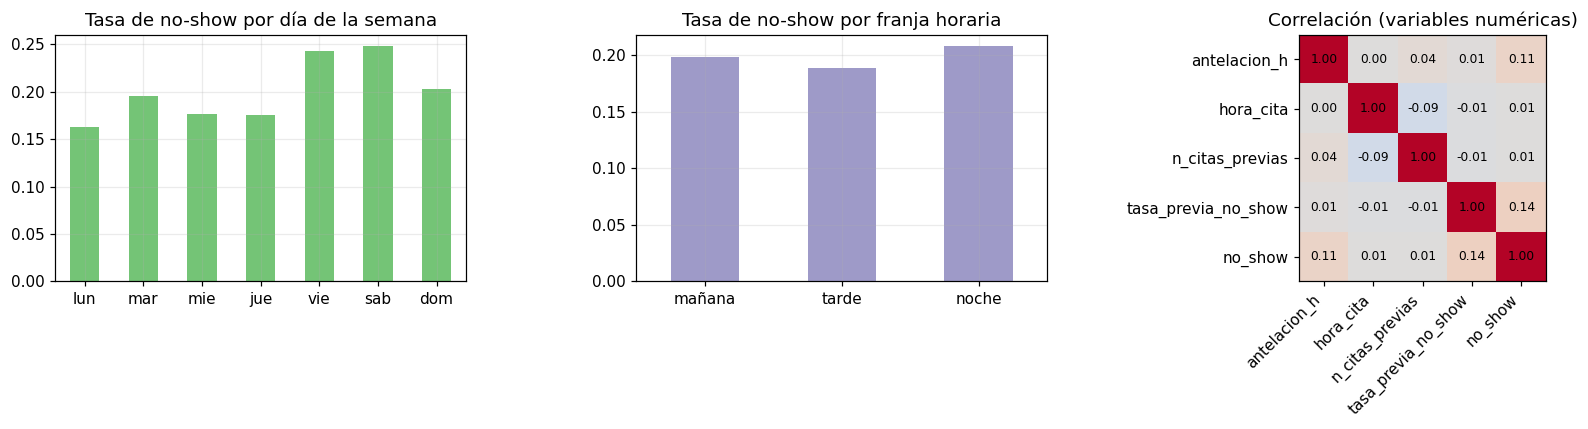

Outliers de antelación (> 30 días): 0 | máx. antelación (h): 250.1


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
t_dia = dm.groupby("dia_semana")["no_show"].mean().reindex(DIAS)
t_dia.plot(kind="bar", ax=ax[0], color="#74c476", rot=0); ax[0].set_title("Tasa de no-show por día de la semana"); ax[0].set_xlabel("")
t_franja = dm.groupby("franja")["no_show"].mean().reindex(["mañana", "tarde", "noche"])
t_franja.plot(kind="bar", ax=ax[1], color="#9e9ac8", rot=0); ax[1].set_title("Tasa de no-show por franja horaria"); ax[1].set_xlabel("")
num = dm[["antelacion_h", "hora_cita", "n_citas_previas", "tasa_previa_no_show", "no_show"]].corr()
im = ax[2].imshow(num, cmap="coolwarm", vmin=-1, vmax=1)
ax[2].set_xticks(range(len(num))); ax[2].set_xticklabels(num.columns, rotation=45, ha="right")
ax[2].set_yticks(range(len(num))); ax[2].set_yticklabels(num.columns); ax[2].grid(False)
for i in range(len(num)):
    for j in range(len(num)): ax[2].text(j, i, f"{num.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[2].set_title("Correlación (variables numéricas)")
plt.tight_layout(); plt.savefig("figuras/eda_2_dia_franja_correlacion.png", bbox_inches="tight"); plt.show()
print("Outliers de antelación (> 30 días):", int((dm["antelacion_h"] > 720).sum()), "| máx. antelación (h):", round(dm["antelacion_h"].max(), 1))

**Conclusión Figura 2.** Compare la tasa de no-show por día de la semana y por franja horaria (completar con los valores de sus gráficos: qué días y franjas concentran más no-shows y cuánto difieren). Las correlaciones con el target son bajas o moderadas (ninguna cercana a 1): la señal existe pero no es trivial, y el desempeño esperado es moderado. La antelación tiene cola larga (reservas con muchos días de adelanto); se acota con una regla de negocio (30 días) en la limpieza.

## 5. Limpieza y transformación
Criterios explícitos (no solo eliminar):
- **Fuera de horario y segundos de registro (aplicado en la sección 3):** se excluyen las citas fuera de 05:00–22:00 (probables registros de prueba) y se anulan los `segundos_registro` fuera de 0–60 s, porque ese campo no es predictor y mide pausas del usuario, no el guardado.
- **Estados:** se modela solo `asistio` / `no_asistio`; `cancelo` y `pendiente` no tienen resultado definido y no se imputan (Contrato de Datos).
- **Duplicados:** el índice único (cliente, servicio, fecha-hora) los bloquea en el MVP; aquí se verifica y se eliminan si aparecen.
- **Nulos:** `recordatorio_enviado_en` y `confirmada_en` nulos significan «no ocurrió» → se convierten en 0/1. `tasa_previa_no_show` es nula sin historial → se imputa con la mediana **del entrenamiento** más un indicador de «sin historial» (dentro del Pipeline).
- **Outliers:** `antelacion_h` se acota a 720 h (30 días) por regla de negocio, sin usar percentiles del dataset.
- **Codificación y escalado:** one-hot para `servicio`, `sede`, `dia_semana`; estandarización de las numéricas (necesaria para regresión logística, KNN o SVM).
- **Variables derivadas (justificadas por el negocio):** `antelacion_h`, `hora_cita`, `fin_de_semana`, `tasa_previa_no_show` y `n_citas_previas` (la misma lógica de riesgo que ya usa el MVP).

In [13]:
dm = dm.drop_duplicates(["id_cliente", "servicio", "fecha_hora_cita"]).copy()
dm["antelacion_h"] = dm["antelacion_h"].clip(lower=0, upper=720)

NUM = ["antelacion_h", "hora_cita", "tasa_previa_no_show", "n_citas_previas"]
CAT = ["servicio", "sede", "dia_semana"]
BIN = ["recordatorio_enviado", "confirmada", "fin_de_semana"]
FEATURES = NUM + CAT + BIN
OBJETIVO = "no_show"

# Variables que podrían filtrar el target y se EXCLUYEN: segundos_registro y marcada_en (se generan al marcar el resultado),
# estado_asistencia (es el target), id_* (identificadores) y los datos personales (no existen en el CSV).
EXCLUIDAS = ["segundos_registro", "marcada_en", "estado_asistencia", "id_cita", "id_cliente"]
print("Predictoras:", FEATURES)
print("Excluidas por fuga/identificación:", EXCLUIDAS)
print("Filas finales del dataset de modelado:", len(dm), "| positivos:", int(dm[OBJETIVO].sum()))

Predictoras: ['antelacion_h', 'hora_cita', 'tasa_previa_no_show', 'n_citas_previas', 'servicio', 'sede', 'dia_semana', 'recordatorio_enviado', 'confirmada', 'fin_de_semana']
Excluidas por fuga/identificación: ['segundos_registro', 'marcada_en', 'estado_asistencia', 'id_cita', 'id_cliente']
Filas finales del dataset de modelado: 950 | positivos: 189


## 6. Partición y prevención de fuga de datos
Partición **70 % entrenamiento / 30 % prueba, estratificada por `no_show` y con `random_state=42`** (Contrato de Datos de APF2). La validación cruzada estratificada de 5 particiones se hace **solo sobre el entrenamiento**. El preprocesamiento (imputación, escalado, codificación) vive dentro de un `Pipeline` + `ColumnTransformer`, de modo que se ajusta únicamente con los datos de entrenamiento de cada partición.

*Nota de fuga:* `tasa_previa_no_show` usa solo citas cerradas anteriores a la cita (≤ cita − 2 h), por lo que no incorpora información futura de la misma fila.

In [14]:
X = dm[FEATURES].copy()
y = dm[OBJETIVO].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print(f"Entrenamiento: {len(X_train)} filas ({y_train.sum()} positivos, {y_train.mean():.1%}) | Prueba: {len(X_test)} filas ({y_test.sum()} positivos, {y_test.mean():.1%})")

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("esc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ("bin", "passthrough", BIN),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def armar(modelo): return Pipeline([("prep", preprocesador), ("clf", modelo)])

Entrenamiento: 665 filas (132 positivos, 19.8%) | Prueba: 285 filas (57 positivos, 20.0%)


## 7. Línea base
Dos referencias: (1) **DummyClassifier** que siempre predice «asistirá»; (2) la **regla heurística que ya usa el MVP** (alto riesgo si el cliente tiene ≥ 30 % de inasistencias en 30 días y al menos 2 citas cerradas). Todo modelo debe superarlas.

In [15]:
def evaluar(nombre, y_true, pred, proba=None):
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba) if proba is not None else np.nan,
            "PR-AUC": average_precision_score(y_true, proba) if proba is not None else np.nan}

dummy = armar(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
heur_train = dm.loc[X_train.index, "riesgo_heuristico_mvp"]       # la regla se calcula con historial previo, sin ajuste de parámetros
heur_test = dm.loc[X_test.index, "riesgo_heuristico_mvp"]
print("Línea base calculada (se reporta sobre test en la sección 10).")
print("Regla heurística del MVP en entrenamiento -> recall:", round(recall_score(y_train, heur_train), 3),
      "| precisión:", round(precision_score(y_train, heur_train, zero_division=0), 3))

Línea base calculada (se reporta sobre test en la sección 10).
Regla heurística del MVP en entrenamiento -> recall: 0.28 | precisión: 0.314


## 8. Modelos de la Unidad 3, hiperparámetros y control de sobreajuste
**Modelos comparados** (misma partición y mismo preprocesamiento): regresión logística (interpretable, base lineal), árbol de decisión (reglas legibles para recepción) y *gradient boosting* (captura interacciones; más complejo).
**Búsqueda en grilla** con validación cruzada estratificada de 5 particiones **solo sobre entrenamiento**, optimizando *average precision* (independiente del umbral).
**Costo de los errores:** un no-show no anticipado (falso negativo) hace perder un turno; un falso positivo solo cuesta un recordatorio por WhatsApp (S/ 0 de API). Por eso se prioriza el **recall** y, para elegir el umbral, la métrica **F2** (pondera el recall dos veces más que la precisión).
**Umbral:** se elige con las probabilidades *out-of-fold* del entrenamiento (nunca con el test), maximizando F2 **con una restricción operativa**: marcar como máximo el 40 % de las citas (`MAX_CARGA`, capacidad de recepción para recordar uno a uno por WhatsApp Web; supuesto por confirmar). Sin esa restricción, marcar casi todas las citas produce un F2 alto pero inútil, porque equivale a recordar a todos.
**Control de sobreajuste:** regularización (`C`), profundidad máxima y hoja mínima del árbol, profundidad/learning rate del boosting, y comparación entrenamiento vs. validación cruzada vs. prueba.

In [16]:
ESPACIOS = {
    "Regresión logística": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                          {"clf__max_depth": [2, 3, 4, 5], "clf__min_samples_leaf": [5, 10, 20]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {"clf__n_estimators": [50, 100], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [1, 2, 3]}),
}

MAX_CARGA = 0.40   # supuesto operativo: recepción puede recordar (WhatsApp Web, uno a uno) a lo sumo al 40 % de las citas; confirmar con recepción

def mejor_umbral(y_true, p, beta=2, max_carga=MAX_CARGA):
    # Maximiza F2 entre los umbrales que no marcan más de max_carga de las citas.
    # Sin esta restricción, con ~20 % de positivos, marcar casi todas las citas da un F2 engañosamente alto.
    ths = np.round(np.arange(0.05, 0.91, 0.01), 2)
    ok = [t for t in ths if (p >= t).mean() <= max_carga] or [float(ths[-1])]
    sc = [fbeta_score(y_true, (p >= t).astype(int), beta=beta, zero_division=0) for t in ok]
    i = int(np.argmax(sc)); return float(ok[i]), float(sc[i])

buscadores, umbrales, filas_cv = {}, {}, []
for nombre, (modelo, grilla) in ESPACIOS.items():
    gs = GridSearchCV(armar(modelo), grilla, scoring="average_precision", cv=cv, n_jobs=1, refit=True)
    gs.fit(X_train, y_train)
    oof = cross_val_predict(gs.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    thr, f2_oof = mejor_umbral(y_train, oof)
    buscadores[nombre], umbrales[nombre] = gs, thr
    p_tr = gs.best_estimator_.predict_proba(X_train)[:, 1]
    filas_cv.append({"Modelo": nombre, "Mejores hiperparámetros": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                     "AP (CV)": gs.best_score_, "AUC entrenamiento": roc_auc_score(y_train, p_tr),
                     "AUC OOF (validación)": roc_auc_score(y_train, oof), "Umbral": thr,
                     "Recall OOF": recall_score(y_train, (oof >= thr).astype(int)),
                     "Precisión OOF": precision_score(y_train, (oof >= thr).astype(int), zero_division=0),
                     "F2 OOF": f2_oof})
resumen_cv = pd.DataFrame(filas_cv).set_index("Modelo")
resumen_cv["Brecha AUC (entren. − valid.)"] = resumen_cv["AUC entrenamiento"] - resumen_cv["AUC OOF (validación)"]
display(resumen_cv.round(3))

,Mejores hiperparámetros,AP (CV),AUC entrenamiento,AUC OOF (validación),Umbral,Recall OOF,Precisión OOF,F2 OOF,Brecha AUC (entren. − valid.)
Modelo,,,,,,,,,
Regresión logística,{'C': 0.01},0.338,0.694,0.639,0.21,0.455,0.286,0.407,0.055
Árbol de decisión,"{'max_depth': 5, 'min_samples_leaf': 10}",0.337,0.795,0.654,0.23,0.568,0.287,0.475,0.141
Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 50}",0.380,0.722,0.685,0.22,0.621,0.363,0.544,0.038


**Lectura del sobreajuste.** Una brecha grande entre el AUC de entrenamiento y el de validación indica sobreajuste. Revise la columna «Brecha AUC» de la tabla: los modelos más flexibles (árbol, boosting) suelen mostrar más brecha que la regresión logística. La complejidad se acotó con la grilla (profundidades pequeñas, `learning_rate` bajo, regularización); el informe debe declarar la brecha y el sobreajuste residual del modelo elegido.

## 9. Selección del modelo (antes de usar el test)
**Regla de selección fijada de antemano:** mayor **F2 out-of-fold** en entrenamiento (con el tope de carga de recordatorios); si varios modelos quedan a ≤ 0,02 del mejor, se prefiere el **más interpretable** (regresión logística > árbol > boosting), porque recepción necesita entender por qué una cita se marca de riesgo.

In [17]:
ORDEN_INTERPRETABILIDAD = {"Regresión logística": 0, "Árbol de decisión": 1, "Gradient Boosting": 2}
mejor = resumen_cv["F2 OOF"].max()
candidatos = [m for m in resumen_cv.index if resumen_cv.loc[m, "F2 OOF"] >= mejor - 0.02]
elegido = min(candidatos, key=lambda m: ORDEN_INTERPRETABILIDAD[m])
umbral_final = umbrales[elegido]
modelo_final = buscadores[elegido].best_estimator_      # ajustado SOLO con entrenamiento
print("Candidatos dentro de 0,02 del mejor F2 OOF:", candidatos)
print("Modelo seleccionado:", elegido, "| umbral:", umbral_final, "| hiperparámetros:", buscadores[elegido].best_params_)

Candidatos dentro de 0,02 del mejor F2 OOF: ['Gradient Boosting']
Modelo seleccionado: Gradient Boosting | umbral: 0.22 | hiperparámetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 1, 'clf__n_estimators': 50}


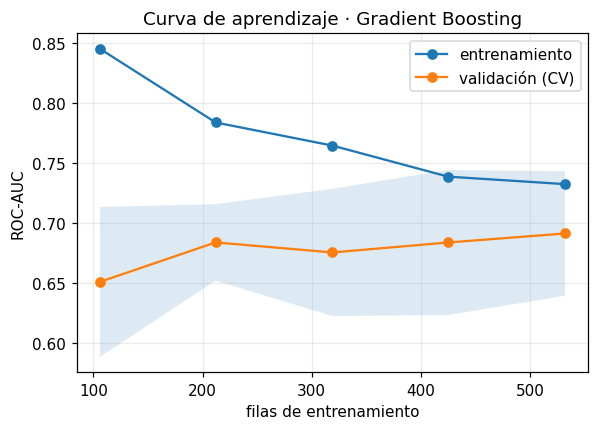

In [18]:
# Curva de aprendizaje del modelo elegido (solo entrenamiento, validación cruzada)
tam, tr_sc, va_sc = learning_curve(modelo_final, X_train, y_train, cv=cv, scoring="roc_auc",
                                   train_sizes=np.linspace(0.2, 1.0, 5), random_state=RANDOM_STATE)
plt.figure(figsize=(6, 4))
plt.plot(tam, tr_sc.mean(1), "o-", label="entrenamiento"); plt.plot(tam, va_sc.mean(1), "o-", label="validación (CV)")
plt.fill_between(tam, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=.15)
plt.title(f"Curva de aprendizaje · {elegido}"); plt.xlabel("filas de entrenamiento"); plt.ylabel("ROC-AUC"); plt.legend()
plt.savefig("figuras/curva_aprendizaje.png", bbox_inches="tight"); plt.show()

## 10. Evaluación en el conjunto de prueba (se usa una sola vez)
El test **no se usó** para elegir hiperparámetros, umbral ni modelo. Aquí solo se reporta el desempeño de todos los modelos y de la línea base con la partición reservada.

In [19]:
filas = []
filas.append(evaluar("Línea base 1: siempre «asistirá»", y_test, dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1]))
filas.append(evaluar("Línea base 2: regla heurística del MVP", y_test, heur_test.to_numpy()))
probas_test = {}
for nombre, gs in buscadores.items():
    p = gs.best_estimator_.predict_proba(X_test)[:, 1]
    probas_test[nombre] = p
    filas.append(evaluar(nombre + (" (seleccionado)" if nombre == elegido else ""), y_test, (p >= umbrales[nombre]).astype(int), p))
tabla_test = pd.DataFrame(filas).set_index("Modelo")
display(tabla_test.round(3))
tabla_test.round(4).to_csv("tabla_metricas_test.csv")

# Ficha de coherencia, criterio 5 (señal ni nula ni perfecta)
sel = tabla_test.loc[elegido + " (seleccionado)"]
print(f"\nCriterio 5 → ROC-AUC = {sel['ROC-AUC']:.3f}, F1 = {sel['F1']:.3f} (< 0,98 y > azar): señal ni nula ni perfecta:",
      "OK" if (sel["ROC-AUC"] < 0.98 and sel["F1"] < 0.98 and sel["ROC-AUC"] > 0.55) else "REVISAR")

,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC
Modelo,,,,,,,
Línea base 1: siempre «asistirá»,0.800,0.000,0.000,0.000,0.000,0.500,0.200
Línea base 2: regla heurística del MVP,0.761,0.359,0.246,0.292,0.262,NaN,NaN
Regresión logística,0.691,0.282,0.351,0.312,0.334,0.666,0.356
Árbol de decisión,0.681,0.288,0.404,0.336,0.373,0.633,0.294
Gradient Boosting (seleccionado),0.723,0.347,0.439,0.388,0.417,0.680,0.372



Criterio 5 → ROC-AUC = 0.680, F1 = 0.388 (< 0,98 y > azar): señal ni nula ni perfecta: OK


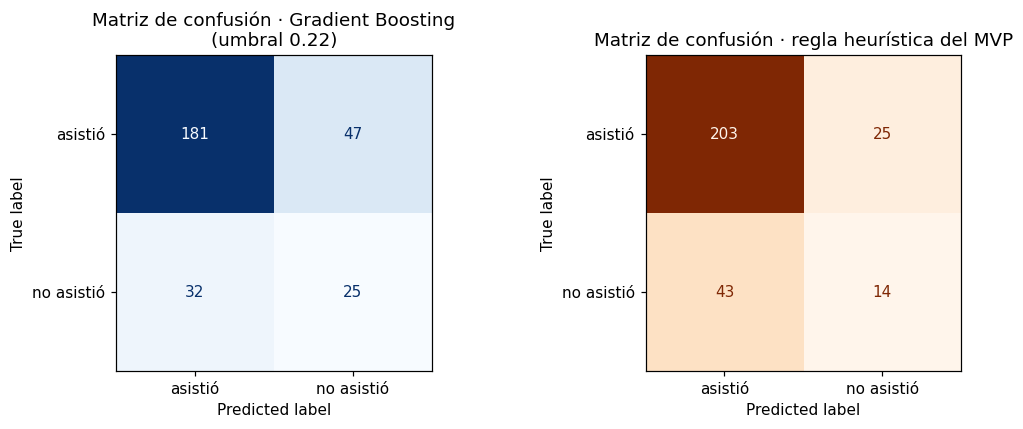

,% de citas a las que se recuerda,% de no-shows alcanzados (recall)
Estrategia,,
Recordar a todas las citas,100.0,100.0
Regla heurística del MVP,13.7,24.6
Modelo (Gradient Boosting),25.3,43.9


In [20]:
p_sel = probas_test[elegido]; pred_sel = (p_sel >= umbral_final).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_sel), display_labels=["asistió", "no asistió"]).plot(ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title(f"Matriz de confusión · {elegido}\n(umbral {umbral_final})"); ax[0].grid(False)
ConfusionMatrixDisplay(confusion_matrix(y_test, heur_test), display_labels=["asistió", "no asistió"]).plot(ax=ax[1], colorbar=False, cmap="Oranges")
ax[1].set_title("Matriz de confusión · regla heurística del MVP"); ax[1].grid(False)
plt.tight_layout(); plt.savefig("figuras/matrices_confusion.png", bbox_inches="tight"); plt.show()

# Carga operativa: a cuántas citas se enviaría recordatorio vs. cuántos no-shows se alcanzan
carga = pd.DataFrame({
    "Estrategia": ["Recordar a todas las citas", "Regla heurística del MVP", f"Modelo ({elegido})"],
    "% de citas a las que se recuerda": [1.0, heur_test.mean(), pred_sel.mean()],
    "% de no-shows alcanzados (recall)": [1.0, recall_score(y_test, heur_test), recall_score(y_test, pred_sel)],
}).set_index("Estrategia")
display((carga * 100).round(1))

In [21]:
# Análisis de errores: ≥ 3 casos donde el modelo falla
an = X_test.copy(); an["prob_no_show"] = p_sel; an["real"] = y_test; an["pred"] = pred_sel
cols_show = ["servicio", "sede", "dia_semana", "hora_cita", "antelacion_h", "confirmada", "recordatorio_enviado",
             "n_citas_previas", "tasa_previa_no_show", "prob_no_show", "real", "pred"]
fn = an[(an["real"] == 1) & (an["pred"] == 0)].sort_values("prob_no_show").head(3)
fp = an[(an["real"] == 0) & (an["pred"] == 1)].sort_values("prob_no_show", ascending=False).head(2)
print("Falsos negativos (no-shows que el modelo NO detectó), los de menor probabilidad:")
display(fn[cols_show].round(2))
print("Falsos positivos (se marcó riesgo y sí asistió), los de mayor probabilidad:")
display(fp[cols_show].round(2))
print("Totales en test -> falsos negativos:", int(((an['real']==1)&(an['pred']==0)).sum()), "| falsos positivos:", int(((an['real']==0)&(an['pred']==1)).sum()))

Falsos negativos (no-shows que el modelo NO detectó), los de menor probabilidad:


,servicio,sede,dia_semana,hora_cita,antelacion_h,confirmada,recordatorio_enviado,n_citas_previas,tasa_previa_no_show,prob_no_show,real,pred
650,gimnasio,Santa Rosa,sab,19.0,6.11,1,1,1,0.0,0.10,1,0
980,sauna,Túpac Amaru,vie,19.0,16.37,1,1,2,0.0,0.10,1,0
12,sauna,Santa Rosa,lun,15.5,3.36,1,0,0,NaN,0.13,1,0


Falsos positivos (se marcó riesgo y sí asistió), los de mayor probabilidad:


,servicio,sede,dia_semana,hora_cita,antelacion_h,confirmada,recordatorio_enviado,n_citas_previas,tasa_previa_no_show,prob_no_show,real,pred
552,gimnasio,Túpac Amaru,mie,20.0,242.89,0,1,4,0.25,0.34,0,1
542,sauna,Túpac Amaru,mie,16.5,49.80,0,0,2,0.50,0.32,0,1


Totales en test -> falsos negativos: 32 | falsos positivos: 47


**Hipótesis de los fallos (completar con sus propios casos).** Mire la celda anterior y escriba, para cada falso negativo y falso positivo, qué variables tenía el caso y por qué el modelo pudo equivocarse. Pistas frecuentes:

- **Falsos negativos con confirmación o recordatorio:** la confirmación reduce el riesgo, pero no garantiza asistencia (ruido irreducible con estas variables).
- **Clientes sin historial (0–1 citas previas):** el modelo casi no tiene información del cliente (*cold start*).
- **Falsos positivos con mucha antelación o en fin de semana:** el modelo pesa esas variables aunque el cliente suela asistir.
- **Límite:** son casos aislados de un conjunto de prueba pequeño; las conclusiones son indicativas y el dataset es simulado o mixto.

## 11. Interpretación: importancia de variables y acciones

,variable,caída de PR-AUC al permutar,desv.
0,confirmada,0.0834,0.0295
1,antelacion_h,0.0631,0.0273
2,recordatorio_enviado,0.0512,0.0214
3,tasa_previa_no_show,0.0504,0.0081
4,hora_cita,0.0000,0.0000
5,n_citas_previas,0.0000,0.0000
6,sede,0.0000,0.0000
7,servicio,0.0000,0.0000
8,dia_semana,0.0000,0.0000
9,fin_de_semana,0.0000,0.0000


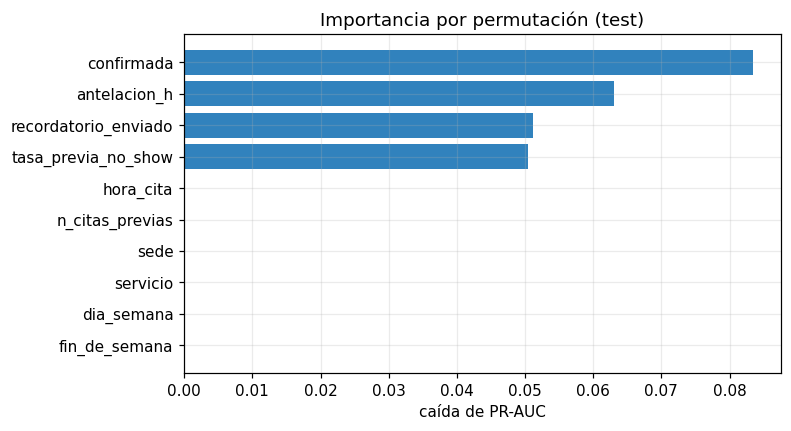

In [22]:
pi = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision", n_repeats=30, random_state=RANDOM_STATE)
imp = pd.DataFrame({"variable": FEATURES, "caída de PR-AUC al permutar": pi.importances_mean, "desv.": pi.importances_std}).sort_values("caída de PR-AUC al permutar", ascending=False)
display(imp.round(4).reset_index(drop=True))
plt.figure(figsize=(7, 4)); plt.barh(imp["variable"][::-1], imp["caída de PR-AUC al permutar"][::-1], color="#3182bd")
plt.title("Importancia por permutación (test)"); plt.xlabel("caída de PR-AUC")
plt.savefig("figuras/permutation_importance.png", bbox_inches="tight"); plt.show()

clf = modelo_final.named_steps["clf"]
nombres = modelo_final.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "coef_"):
    coef = pd.DataFrame({"variable": nombres, "coeficiente": clf.coef_[0], "razón de momios (OR)": np.exp(clf.coef_[0])}).sort_values("coeficiente")
    print("Coeficientes de la regresión logística (variables numéricas estandarizadas):")
    display(coef.round(3).reset_index(drop=True))
elif hasattr(clf, "tree_"):
    print(export_text(clf, feature_names=list(nombres)))

## 12. Exportación del modelo e integración con el MVP
Se exporta el **pipeline completo** (preprocesamiento + modelo) con `joblib`, junto con el umbral y metadatos. El script `predecir.py` carga el archivo y responde a un registro con **el esquema que el MVP ya captura** (tabla `citas`) más el historial del cliente (agregado que hoy calcula `riesgo_clientes()` en Supabase).

In [23]:
VERSION_MODELO = "apf3-g04-v1"
bundle = {
    "pipeline": modelo_final, "umbral": umbral_final, "features": FEATURES, "nombre_modelo": elegido,
    "version_modelo": VERSION_MODELO, "sklearn": sklearn.__version__, "random_state": RANDOM_STATE,
    "entrenado_con": {"filas": int(len(X_train)), "positivos": int(y_train.sum()), "origen": "simulado"},
    "metricas_test": {k: round(float(v), 4) for k, v in sel.items()},
}
joblib.dump(bundle, "modelo_no_show.joblib", compress=3)
print("Modelo exportado:", "modelo_no_show.joblib", f"({os.path.getsize('modelo_no_show.joblib')/1024:.1f} KB)")

Modelo exportado: modelo_no_show.joblib (9.7 KB)


In [24]:
%%writefile predecir.py
'''predecir.py · APF3 Grupo 04 · LA CASCADA E.I.R.L.
Carga el modelo exportado y devuelve la probabilidad de no-show de una cita con el esquema del MVP.
Uso:   python predecir.py ejemplo_entrada.json        (acepta un objeto o una lista de objetos)
Import: from predecir import predecir
'''
import os, sys, json, warnings
import joblib
import sklearn
import numpy as np
import pandas as pd

RUTA_MODELO = os.path.join(os.path.dirname(os.path.abspath(__file__)), "modelo_no_show.joblib")
TZ = "America/Lima"
DIAS = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]
SERVICIOS, SEDES = {"sauna", "gimnasio"}, {"Túpac Amaru", "Santa Rosa", "Año Nuevo"}
_BUNDLE = None


def cargar_modelo(ruta=RUTA_MODELO):
    global _BUNDLE
    if _BUNDLE is None:
        _BUNDLE = joblib.load(ruta)
        if _BUNDLE.get("sklearn") != sklearn.__version__:
            warnings.warn(f"El modelo se entrenó con scikit-learn {_BUNDLE.get('sklearn')} y se carga con {sklearn.__version__}; "
                          "instala la misma versión (ver requirements.txt).")
    return _BUNDLE


def _ts(valor):
    return None if valor in (None, "") else pd.Timestamp(valor).tz_convert(TZ) if pd.Timestamp(valor).tzinfo else pd.Timestamp(valor).tz_localize(TZ)


def construir_features(r):
    # Misma lógica que la preparación del notebook (evita desfase entre entrenamiento y producción).
    faltan = [k for k in ("servicio", "sede", "fecha_hora_cita", "fecha_hora_registro") if not r.get(k)]
    if faltan:
        raise ValueError(f"Faltan campos obligatorios: {faltan}")
    if r["servicio"] not in SERVICIOS or r["sede"] not in SEDES:
        raise ValueError("servicio o sede fuera de los valores permitidos")
    cita, reg = _ts(r["fecha_hora_cita"]), _ts(r["fecha_hora_registro"])
    if cita < reg:
        raise ValueError("fecha_hora_cita no puede ser anterior a fecha_hora_registro")
    h = r.get("historial_30d") or {}
    n = int(h.get("citas_cerradas", 0)); ns = int(h.get("no_shows", 0))
    if ns > n:
        raise ValueError("historial_30d: no_shows no puede superar citas_cerradas")
    fila = {
        "antelacion_h": float(np.clip((cita - reg).total_seconds() / 3600, 0, 720)),
        "hora_cita": cita.hour + cita.minute / 60,
        "tasa_previa_no_show": ns / n if n > 0 else np.nan,
        "n_citas_previas": n,
        "servicio": r["servicio"],
        "sede": "Túpac Amaru" if r["sede"] == "Año Nuevo" else r["sede"],
        "dia_semana": DIAS[cita.dayofweek],
        "recordatorio_enviado": int(bool(r.get("recordatorio_enviado_en"))),
        "confirmada": int(bool(r.get("confirmada_en"))),
        "fin_de_semana": int(cita.dayofweek >= 5),
    }
    return pd.DataFrame([fila])


def predecir(registro):
    b = cargar_modelo()
    X = construir_features(registro)[b["features"]]
    p = float(b["pipeline"].predict_proba(X)[:, 1][0])
    alto = p >= b["umbral"]
    return {
        "id_cita": registro.get("id_cita"),
        "prob_no_show": round(p, 4),
        "umbral": b["umbral"],
        "pred_no_show": int(alto),
        "nivel_riesgo": "alto" if alto else "bajo",
        "accion_sugerida": ("Enviar recordatorio por WhatsApp (wa.me) y pedir confirmación; priorizar en «Citas por recordar»"
                            if alto else "Sin acción adicional"),
        "version_modelo": b["version_modelo"],
    }


if __name__ == "__main__":
    ruta = sys.argv[1] if len(sys.argv) > 1 else "ejemplo_entrada.json"
    with open(ruta, encoding="utf-8") as f:
        datos = json.load(f)
    salida = [predecir(x) for x in datos] if isinstance(datos, list) else predecir(datos)
    print(json.dumps(salida, ensure_ascii=False, indent=2))

Writing predecir.py


In [25]:
# Dos registros de ejemplo con el esquema del MVP (campos de la tabla citas + historial del cliente a 30 días)
ejemplos = [
  {"id_cita": "ejemplo-001", "id_cliente": "uuid-cliente-A", "servicio": "sauna", "sede": "Túpac Amaru",
   "fecha_hora_cita": "2026-10-24T23:30:00+00:00", "fecha_hora_registro": "2026-10-16T15:00:00+00:00",
   "recordatorio_enviado_en": None, "confirmada_en": None,
   "historial_30d": {"citas_cerradas": 3, "no_shows": 2}},
  {"id_cita": "ejemplo-002", "id_cliente": "uuid-cliente-B", "servicio": "gimnasio", "sede": "Santa Rosa",
   "fecha_hora_cita": "2026-10-20T12:00:00+00:00", "fecha_hora_registro": "2026-10-20T07:00:00+00:00",
   "recordatorio_enviado_en": "2026-10-20T08:30:00+00:00", "confirmada_en": "2026-10-20T09:10:00+00:00",
   "historial_30d": {"citas_cerradas": 0, "no_shows": 0}},
]
with open("ejemplo_entrada.json", "w", encoding="utf-8") as f:
    json.dump(ejemplos, f, ensure_ascii=False, indent=2)
print("Llamada real al modelo exportado (script independiente):\n")
res = !python predecir.py ejemplo_entrada.json
salida_txt = "\n".join(res)
print(salida_txt)
with open("ejemplo_salida.json", "w", encoding="utf-8") as f:
    f.write(salida_txt)

Llamada real al modelo exportado (script independiente):

[
  {
    "id_cita": "ejemplo-001",
    "prob_no_show": 0.3231,
    "umbral": 0.22,
    "pred_no_show": 1,
    "nivel_riesgo": "alto",
    "accion_sugerida": "Enviar recordatorio por WhatsApp (wa.me) y pedir confirmación; priorizar en «Citas por recordar»",
    "version_modelo": "apf3-g04-v1"
  },
  {
    "id_cita": "ejemplo-002",
    "prob_no_show": 0.0983,
    "umbral": 0.22,
    "pred_no_show": 0,
    "nivel_riesgo": "bajo",
    "accion_sugerida": "Sin acción adicional",
    "version_modelo": "apf3-g04-v1"
  }
]


In [26]:
# Verificación de consistencia: la predicción del script debe coincidir con el pipeline entrenado (sin desfase)
import importlib, predecir
importlib.reload(predecir)
muestra = dm.loc[X_test.index].sample(40, random_state=RANDOM_STATE)
maxdif = 0.0
for _, f in muestra.iterrows():
    reg = {"servicio": f["servicio"], "sede": f["sede"],
           "fecha_hora_cita": f["fecha_hora_cita"].isoformat(), "fecha_hora_registro": f["fecha_hora_registro"].isoformat(),
           "recordatorio_enviado_en": f["recordatorio_enviado_en"].isoformat() if pd.notna(f["recordatorio_enviado_en"]) else None,
           "confirmada_en": f["confirmada_en"].isoformat() if pd.notna(f["confirmada_en"]) else None,
           "historial_30d": {"citas_cerradas": int(f["n_citas_previas"]), "no_shows": int(f["n_no_show_previos"])}}
    p_script = predecir.predecir(reg)["prob_no_show"]
    p_pipe = float(modelo_final.predict_proba(X_test.loc[[f.name]])[:, 1][0])
    maxdif = max(maxdif, abs(p_script - p_pipe))
print("Diferencia máxima entre predecir.py y el pipeline (40 citas de test):", round(maxdif, 5))
assert maxdif < 1e-3, "Desfase entre entrenamiento y servicio"

# Viabilidad de despliegue: tiempo de predicción y tamaño
t0 = time.perf_counter()
for _ in range(200): predecir.predecir(ejemplos[0])
ms = (time.perf_counter() - t0) / 200 * 1000
print(f"Tiempo medio por predicción: {ms:.1f} ms | tamaño del modelo: {os.path.getsize('modelo_no_show.joblib')/1024:.1f} KB")

Diferencia máxima entre predecir.py y el pipeline (40 citas de test): 5e-05
Tiempo medio por predicción: 10.7 ms | tamaño del modelo: 9.7 KB


## 13. Resumen para el informe

In [27]:
resumen = {
    "filas_dataset": int(len(dm)), "positivos": int(dm["no_show"].sum()), "tasa_no_show": round(float(dm["no_show"].mean()), 4),
    "train/test": [int(len(X_train)), int(len(X_test))],
    "modelo_seleccionado": elegido, "umbral": umbral_final,
    "metricas_test_modelo": {k: round(float(v), 3) for k, v in sel.items()},
    "metricas_test_heuristica_mvp": {k: round(float(v), 3) for k, v in tabla_test.loc["Línea base 2: regla heurística del MVP"].items() if k in ("Precision", "Recall", "F1", "F2")},
    "carga_recordatorios_modelo": round(float(pred_sel.mean()), 3),
    "tiempo_prediccion_ms": round(ms, 1), "random_state": RANDOM_STATE,
}
with open("resumen_apf3.json", "w", encoding="utf-8") as f: json.dump(resumen, f, ensure_ascii=False, indent=2)
print(json.dumps(resumen, ensure_ascii=False, indent=2))

{
  "filas_dataset": 950,
  "positivos": 189,
  "tasa_no_show": 0.1989,
  "train/test": [
    665,
    285
  ],
  "modelo_seleccionado": "Gradient Boosting",
  "umbral": 0.22,
  "metricas_test_modelo": {
    "Accuracy": 0.723,
    "Precision": 0.347,
    "Recall": 0.439,
    "F1": 0.388,
    "F2": 0.417,
    "ROC-AUC": 0.68,
    "PR-AUC": 0.372
  },
  "metricas_test_heuristica_mvp": {
    "Precision": 0.359,
    "Recall": 0.246,
    "F1": 0.292,
    "F2": 0.262
  },
  "carga_recordatorios_modelo": 0.253,
  "tiempo_prediccion_ms": 10.7,
  "random_state": 42
}
